# E-commerce: LSTM so với RNN (cùng dữ liệu, cùng siêu tham số)

**Nhóm 5:** Nguyễn Phú Đại · Trần Vũ Tiến Minh · Trần Đình Hiếu · Phạm Thanh An

Notebook này đặt **LSTM** cạnh **RNN** trên đúng bài toán của `A6/source/ecommerce.ipynb`:

- **Dữ liệu:** Pakistan's Largest E-Commerce Dataset, khoảng 407 nghìn đơn hàng của 115 nghìn khách hàng (07/2016 → 08/2018).
- **Bài toán:** khi khách đặt một đơn, dự đoán đơn đó sẽ kết thúc ra sao: **completed**, **canceled** hay **refunded** (phân loại 3 lớp, *many-to-one*). Đầu vào là chuỗi 8 đơn gần nhất của khách; bước thứ 8 là đơn cần dự đoán.

**Thiết kế để so sánh công bằng.** Mọi thứ giống notebook RNN, chỉ khác lớp hồi quy:

| | RNN (A6) | LSTM (notebook này) |
|---|---|---|
| Tiền xử lý, 46 đặc trưng/bước, chia train / val / test theo thời gian | giống hệt (code chép nguyên từ A6) | giống hệt |
| Kiến trúc | `nn.RNN(46→64)` → `nn.RNN(64→32)` → `Linear(32→3)` | `nn.LSTM(46→64)` → `nn.LSTM(64→32)` → `Linear(32→3)` |
| Huấn luyện | Adam lr 1e-3, batch 256, 15 epoch, clip 1.0, giữ epoch có val loss thấp nhất | giống hệt |
| Khởi tạo | Glorot (W_x), trực giao (W_h), bias 0 | giống hệt; riêng bias cổng quên = 1 (mặc định của Keras) |

Mỗi mô hình chạy **5 seed** (42, 0, 1, 2, 3) để thấy độ dao động. RNN với seed 42 dùng đúng trọng số khởi tạo và thứ tự batch của A6, nên phải ra lại đúng kết quả A6 (accuracy 0.6625, log loss 0.7545). Đây là bước kiểm tra tái lập.

**Mục lục**
1. Thiết lập
2. Tiền xử lý (chép từ A6)
3. Mô hình RNN và LSTM
4. Huấn luyện (2 mô hình × 5 seed)
5. So sánh: chỉ số trên tập test
6. Đường học
7. Lịch sử khách hàng giúp được bao nhiêu?
8. Mô hình nhìn vào bước nào? (độ nhạy theo thời gian)
9. Ma trận nhầm lẫn và chi phí
10. Lưu kết quả và kết luận

## 1. Thiết lập

Hằng số giống `A6/source/ecommerce.ipynb`. Dữ liệu đọc từ thư mục `A6/data/`; nếu không có thì `kagglehub` tải về. Hình lưu vào `experiment/figures/`, số liệu tổng hợp lưu vào `experiment/results/lstm_ecommerce.json` (để dùng cho slide sau này).

In [1]:
import copy
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score, matthews_corrcoef,
                             roc_auc_score, log_loss, confusion_matrix)

import torch
import torch.nn as nn
from torch import Tensor

torch.set_flush_denormal(True)
torch.set_num_threads(4)

SEED          = 42
SEEDS         = [42, 0, 1, 2, 3]
SEQ_LEN       = 8               # orders per input sequence: 7 earlier orders + the predicted order
OUTCOME_DELAY = 14              # days after which the outcome of an earlier order is known
H1, H2        = 64, 32          # hidden units of recurrent layer 1 and layer 2
BATCH_SIZE    = 256
EPOCHS        = 15
LR            = 1e-3
BETA1         = 0.9
BETA2         = 0.999
EPS           = 1e-7
CLIP          = 1.0             # maximum global gradient norm

VAL_START  = pd.Timestamp('2018-01-01')     # validation: orders from 2018-01-01 to 2018-03-31
TEST_START = pd.Timestamp('2018-04-01')     # test:       orders from 2018-04-01 to 2018-08-28

CLASSES = ['completed', 'canceled', 'refunded']
C       = len(CLASSES)
STATUS_TO_CLASS = {'complete': 0, 'received': 0, 'closed': 0, 'canceled': 1, 'order_refunded': 2, 'refund': 2}

A6_DIR    = Path('../../Phát triển hệ thống thông minh/A6')
DATA_DIR  = A6_DIR / 'data' / 'pakistans-largest-ecommerce-dataset'
DATA_FILE = DATA_DIR / 'Pakistan Largest Ecommerce Dataset.csv'
if not DATA_FILE.exists():
    import kagglehub, shutil
    DATA_DIR = Path('data/pakistans-largest-ecommerce-dataset')
    DATA_FILE = DATA_DIR / 'Pakistan Largest Ecommerce Dataset.csv'
    shutil.copytree(kagglehub.dataset_download('zusmani/pakistans-largest-ecommerce-dataset'), DATA_DIR, dirs_exist_ok=True)
FIG_DIR    = Path('figures')
RESULT_DIR = Path('results')
FIG_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

# Results of the PyTorch RNN in A6/source/ecommerce.ipynb (section 13), used to check that the RNN here is the same run
A6_RNN = {'accuracy': 0.6625, 'macro F1': 0.5134, 'log loss': 0.7545, 'ROC-AUC': 0.7926}

CELLS        = ['RNN', 'LSTM']
COLORS       = {'RNN': '#eb6834', 'LSTM': '#2a78d6', 'LR, last order': '#9a9a9a', 'LR, 8 orders flat': '#7a5cc4', 'majority class': '#c4a35a'}
CLASS_COLORS = {'completed': '#1baf7a', 'canceled': '#d62728', 'refunded': '#eb6834', 'unfinished': '#c9c9c9'}

np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.alpha': 0.3,
    'lines.linewidth': 2,
})

print(f'numpy {np.__version__} | pandas {pd.__version__} | torch {torch.__version__} | torch threads: {torch.get_num_threads()}')
print('data file:', DATA_FILE.resolve())

numpy 2.4.6 | pandas 3.0.3 | torch 2.14.0+cpu | torch threads: 4
data file: /home/storie/Code/Phát triển hệ thống thông minh/A6/data/pakistans-largest-ecommerce-dataset/Pakistan Largest Ecommerce Dataset.csv


## 2. Tiền xử lý (chép nguyên từ A6)

Các ô dưới đây là code của `A6/source/ecommerce.ipynb` (mục 2.1, 3.1, 3.2, 5.1, 5.2, 6.1, 6.2), bỏ các biểu đồ phân tích dữ liệu. Giải thích chi tiết từng bước nằm trong notebook A6.

### 2.1 Đọc file, bỏ dòng và cột rỗng

In [2]:
raw = pd.read_csv(DATA_FILE, low_memory=False)

blank_rows = raw.isna().all(axis=1)
blank_cols = raw.columns[raw.isna().all()]
print(f'shape {raw.shape} | completely empty rows: {blank_rows.sum():,} | completely empty columns: {list(blank_cols)}')

items = raw.loc[~blank_rows].drop(columns=blank_cols)
items.columns = items.columns.str.strip()
print(f'after removing them: {items.shape[0]:,} order lines, {items.shape[1]} columns | duplicated rows: {items.duplicated().sum()} | '
      f'duplicated item_id: {items.item_id.duplicated().sum()}')

pd.DataFrame({
    'dtype':    items.dtypes.astype(str),
    'missing':  items.isna().sum(),
    '\\N':      (items == '\\N').sum(),
    'distinct': items.nunique(),
    'example':  items.iloc[1000],
})

shape (1048575, 26) | completely empty rows: 464,051 | completely empty columns: ['Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']


after removing them: 584,524 order lines, 21 columns | duplicated rows: 0 | duplicated item_id: 0


,dtype,missing,\N,distinct,example
item_id,float64,0,0,584524,212294.0
status,str,15,4,16,complete
created_at,str,0,0,789,7/3/2016
sku,str,20,0,84889,ESPICO_Classic Cotton-Skin-42
price,float64,0,0,9121,350.0
qty_ordered,float64,0,0,74,1.0
grand_total,float64,0,0,36829,250.0
increment_id,str,0,0,408782,100148203
category_name_1,str,164,7850,16,Women's Fashion
sales_commission_code,str,137178,339001,7225,\N


### 2.2 Làm sạch: bỏ cột trùng lặp / rò rỉ nhãn, bỏ đơn chưa kết thúc

In [3]:
lines = items.drop(columns=['BI Status', 'MV', 'Working Date', 'Year', 'Month', 'M-Y', 'FY', 'Customer Since', 'sku', 'sales_commission_code'])
print(f'lines: {len(lines):,}')

lines = lines[lines['Customer ID'].notna()]
print(f'with a customer: {len(lines):,}')

lines = lines[lines.status.isin(STATUS_TO_CLASS)].assign(
    date     = lambda d: pd.to_datetime(d.created_at, format='%m/%d/%Y'),
    category = lambda d: d.category_name_1.replace('\\N', np.nan).fillna('unknown'),
    value    = lambda d: d.price.clip(lower=0) * d.qty_ordered,
    cls      = lambda d: d.status.map(STATUS_TO_CLASS),
)
print(f'with a final status: {len(lines):,} lines in {lines.increment_id.nunique():,} orders of {lines["Customer ID"].nunique():,} customers')
lines.head()

lines: 584,524
with a customer: 584,513


with a final status: 580,286 lines in 407,445 orders of 115,012 customers


,item_id,status,created_at,price,qty_ordered,grand_total,increment_id,category_name_1,discount_amount,payment_method,Customer ID,date,category,value,cls
0,211131.0,complete,7/1/2016,1950.0,1.0,1950.0,100147443,Women's Fashion,0.0,cod,1.0,2016-07-01,Women's Fashion,1950.0,0
1,211133.0,canceled,7/1/2016,240.0,1.0,240.0,100147444,Beauty & Grooming,0.0,cod,2.0,2016-07-01,Beauty & Grooming,240.0,1
2,211134.0,canceled,7/1/2016,2450.0,1.0,2450.0,100147445,Women's Fashion,0.0,cod,3.0,2016-07-01,Women's Fashion,2450.0,1
3,211135.0,complete,7/1/2016,360.0,1.0,60.0,100147446,Beauty & Grooming,300.0,cod,4.0,2016-07-01,Beauty & Grooming,360.0,0
4,211136.0,order_refunded,7/1/2016,555.0,2.0,1110.0,100147447,Soghaat,0.0,cod,5.0,2016-07-01,Soghaat,1110.0,2


### 2.3 Mỗi đơn hàng một dòng

In [4]:
orders = lines.groupby('increment_id').agg(
    date       = ('date', 'first'),
    customer   = ('Customer ID', 'first'),
    payment    = ('payment_method', 'first'),
    cls        = ('cls', 'first'),
    items      = ('item_id', 'size'),
    qty        = ('qty_ordered', 'sum'),
    value      = ('value', 'sum'),
    discount   = ('discount_amount', 'sum'),
    first_item = ('item_id', 'min'),
)
CATEGORIES = sorted(lines.category.unique())
orders = orders.join(pd.crosstab(lines.increment_id, lines.category).clip(upper=1).add_prefix('cat: '))
orders = orders.sort_values(['customer', 'date', 'first_item']).reset_index()

orders['k']   = orders.groupby('customer').cumcount()
orders['gap'] = orders.groupby('customer').date.diff().dt.days
orders['outcome'] = np.array(CLASSES)[orders.cls]

print(f'{len(orders):,} orders | {orders.customer.nunique():,} customers | {orders.date.min().date()} .. {orders.date.max().date()} | {len(CATEGORIES)} categories')
print('class shares:', orders.outcome.value_counts(normalize=True).round(4).to_dict())
orders.head()

407,445 orders | 115,012 customers | 2016-07-01 .. 2018-08-28 | 16 categories
class shares: {'completed': 0.5047, 'canceled': 0.3648, 'refunded': 0.1305}


,increment_id,date,customer,payment,cls,items,qty,value,discount,first_item,...,cat: Mobiles & Tablets,cat: Others,cat: School & Education,cat: Soghaat,cat: Superstore,cat: Women's Fashion,cat: unknown,k,gap,outcome
0,100147443,2016-07-01,1.0,cod,0,1,1.0,1950.0,0.0,211131.0,...,0,0,0,0,0,1,0,0,NaN,completed
1,100147444,2016-07-01,2.0,cod,1,1,1.0,240.0,0.0,211133.0,...,0,0,0,0,0,0,0,0,NaN,canceled
2,100222998,2016-11-25,2.0,jazzvoucher,1,1,1.0,270.0,0.0,324257.0,...,0,0,0,1,0,0,0,1,147.0,canceled
3,100147445,2016-07-01,3.0,cod,1,1,1.0,2450.0,0.0,211134.0,...,0,0,0,0,0,1,0,0,NaN,canceled
4,100306394,2017-05-19,3.0,cod,0,4,4.0,1245.0,0.0,473369.0,...,1,0,0,0,0,0,0,1,322.0,completed


### 2.4 Đặc trưng của một đơn (chuẩn hóa bằng thống kê của tập train)

In [5]:
fit = (orders.date < VAL_START).to_numpy()

numeric = pd.DataFrame({
    'value':    np.log1p(orders.value),
    'items':    np.log1p(orders['items']),
    'qty':      np.log1p(orders.qty),
    'discount': (orders.discount / orders.value.where(orders.value > 0)).clip(0, 1).fillna(0),
    'gap_days': np.log1p(orders.gap.fillna(0)),
})
stats = numeric[fit].agg(['mean', 'std'])
numeric = (numeric - stats.loc['mean']) / stats.loc['std']
numeric['first_order'] = (orders.k == 0).astype(float)

PAYMENTS = orders.payment[fit].value_counts().loc[lambda c: c >= 500].index.tolist()
PAYMENT_TYPES = {'cod': 'cash on delivery', 'cashatdoorstep': 'cash on delivery', 'easypay_voucher': 'voucher', 'jazzvoucher': 'voucher',
                 'customercredit': 'store credit', 'productcredit': 'store credit', 'financesettlement': 'store credit', 'marketingexpense': 'store credit'}
payment_type = orders.payment.map(PAYMENT_TYPES).fillna('online')
payment = pd.DataFrame({f'pay: {p}': (orders.payment == p).astype(float) for p in PAYMENTS} | {'pay: other': (~orders.payment.isin(PAYMENTS)).astype(float)}
                       | {f'type: {t}': (payment_type == t).astype(float) for t in ['cash on delivery', 'online', 'voucher', 'store credit']})
month = pd.DataFrame({'month_sin': np.sin(2 * np.pi * orders.date.dt.month / 12), 'month_cos': np.cos(2 * np.pi * orders.date.dt.month / 12)})

static = pd.concat([numeric, payment, orders[[f'cat: {c}' for c in CATEGORIES]].astype(float), month], axis=1)
STATIC = list(static.columns)
static = static.to_numpy('float32')

print(f'{len(STATIC)} static features per order: {STATIC}')
print('payment type of each method:', orders.groupby('payment').payment.first().map(PAYMENT_TYPES).fillna('online').to_dict())
stats.round(4)

40 static features per order: ['value', 'items', 'qty', 'discount', 'gap_days', 'first_order', 'pay: cod', 'pay: Payaxis', 'pay: Easypay', 'pay: easypay_voucher', 'pay: jazzwallet', 'pay: jazzvoucher', 'pay: Easypay_MA', 'pay: customercredit', 'pay: ublcreditcard', 'pay: mcblite', 'pay: cashatdoorstep', 'pay: other', 'type: cash on delivery', 'type: online', 'type: voucher', 'type: store credit', 'cat: Appliances', 'cat: Beauty & Grooming', 'cat: Books', 'cat: Computing', 'cat: Entertainment', 'cat: Health & Sports', 'cat: Home & Living', 'cat: Kids & Baby', "cat: Men's Fashion", 'cat: Mobiles & Tablets', 'cat: Others', 'cat: School & Education', 'cat: Soghaat', 'cat: Superstore', "cat: Women's Fashion", 'cat: unknown', 'month_sin', 'month_cos']
payment type of each method: {'Easypay': 'online', 'Easypay_MA': 'online', 'Payaxis': 'online', 'apg': 'online', 'bankalfalah': 'online', 'cashatdoorstep': 'cash on delivery', 'cod': 'cash on delivery', 'customercredit': 'store credit', 'easypa

,value,items,qty,discount,gap_days
mean,7.6616,0.8288,0.8805,0.0792,0.7208
std,1.7329,0.3070,0.3845,0.1474,1.3690


### 2.5 Chuỗi 8 đơn của mỗi khách

Mỗi bước có 40 đặc trưng của đơn + 6 đặc trưng chuỗi: kết quả của đơn cũ (chỉ khi đơn đó đã cũ hơn 14 ngày), tuổi của đơn, cờ "bước có thật", cờ "đơn cần dự đoán".

In [6]:
SEQUENCE = ['past: completed', 'past: canceled', 'past: refunded', 'age', 'real', 'current']
INPUTS   = STATIC + SEQUENCE
F        = len(INPUTS)

k     = orders.k.to_numpy()
idx   = np.stack([np.where(k >= SEQ_LEN - 1 - j, np.arange(len(orders)) - (SEQ_LEN - 1 - j), -1) for j in range(SEQ_LEN)], axis=1)  # (N, 8)
real  = idx >= 0
safe  = np.where(real, idx, 0)
day   = orders.date.to_numpy().astype('datetime64[D]').astype(int)
age   = (day[:, None] - day[safe]) * real                                          # days between each step and the predicted order
known = real & (age >= OUTCOME_DELAY)
known[:, -1] = False

X = np.concatenate([
    static[safe] * real[..., None],                                                # (N, 8, 40)  order features, 0 on empty steps
    np.eye(C, dtype='float32')[orders.cls.to_numpy()[safe]] * known[..., None],    # (N, 8, 3)   outcome of earlier orders, if known
    (np.log1p(age) / np.log1p(365))[..., None],                                    # (N, 8, 1)
    real[..., None],                                                               # (N, 8, 1)
    np.eye(SEQ_LEN)[-1][None, :, None].repeat(len(orders), axis=0),                # (N, 8, 1)   1 at the last step
], axis=2).astype('float32')
y = orders.cls.to_numpy().astype('int64')                                          # (N,)

print(f'X {X.shape} (orders, steps, inputs), {X.nbytes / 1e9:.2f} GB | y {y.shape} | NaN in X: {np.isnan(X).sum()}')
print(f'real orders per sequence: {dict(enumerate(np.bincount(real.sum(1))[1:].tolist(), start=1))}')
print(f'earlier orders with a known outcome: {known.sum():,} of {real[:, :-1].sum():,} ({known.sum() / real[:, :-1].sum():.1%})')

X (407445, 8, 46) (orders, steps, inputs), 0.60 GB | y (407445,) | NaN in X: 0
real orders per sequence: {1: 115012, 2: 52936, 3: 33412, 4: 23991, 5: 16505, 6: 12835, 7: 10395, 8: 142359}
earlier orders with a known outcome: 441,642 of 1,380,811 (32.0%)


### 2.6 Chia train / validation / test theo thời gian

| Phần | Đơn đặt trong | Dùng để |
|---|---|---|
| train | 2016-07-01 … 2017-12-31 | cập nhật trọng số |
| validation | 2018-01-01 … 2018-03-31 | chọn epoch tốt nhất |
| test | 2018-04-01 … 2018-08-28 | chỉ để so sánh cuối cùng |

In [7]:
split = np.select([orders.date < VAL_START, orders.date < TEST_START], ['train', 'val'], 'test')

X_train, y_train = X[split == 'train'], y[split == 'train']
X_val,   y_val   = X[split == 'val'],   y[split == 'val']
X_test,  y_test  = X[split == 'test'],  y[split == 'test']
test_orders = orders[split == 'test'].reset_index(drop=True)
del X

summary = pd.crosstab(split, orders.outcome)[CLASSES].loc[['train', 'val', 'test']]
display(summary.assign(orders=summary.sum(axis=1)).join(summary.div(summary.sum(axis=1), axis=0).round(3), rsuffix=' share'))
print(f'X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}')

outcome,completed,canceled,refunded,orders,completed share,canceled share,refunded share
row_0,,,,,,,
train,155486,95173,42279,292938,0.531,0.325,0.144
val,28381,29208,4974,62563,0.454,0.467,0.080
test,21772,24270,5902,51944,0.419,0.467,0.114


X_train (292938, 8, 46) | X_val (62563, 8, 46) | X_test (51944, 8, 46)


### 2.7 Mô hình tham chiếu (không hồi quy)

- **majority class**: luôn đoán lớp phổ biến nhất của tập train;
- **LR, last order**: hồi quy logistic chỉ trên đơn cần dự đoán (bước 8), không có lịch sử;
- **LR, 8 orders flat**: hồi quy logistic trên cả 8 × 46 đầu vào đặt cạnh nhau, cùng thông tin với RNN/LSTM nhưng không có trạng thái ẩn.

In [8]:
start = time.perf_counter()
reference_models = {
    'LR, last order':    LogisticRegression(max_iter=1000).fit(X_train[:, -1], y_train),
    'LR, 8 orders flat': LogisticRegression(max_iter=1000).fit(X_train.reshape(len(X_train), -1), y_train),
}
print(f'fitting time {time.perf_counter() - start:.1f}s')

prior = np.bincount(y_train, minlength=C) / len(y_train)
references = {
    'majority class':    {'val': np.tile(prior, (len(y_val), 1)), 'test': np.tile(prior, (len(y_test), 1))},
    'LR, last order':    {'val': reference_models['LR, last order'].predict_proba(X_val[:, -1]),
                          'test': reference_models['LR, last order'].predict_proba(X_test[:, -1])},
    'LR, 8 orders flat': {'val': reference_models['LR, 8 orders flat'].predict_proba(X_val.reshape(len(X_val), -1)),
                          'test': reference_models['LR, 8 orders flat'].predict_proba(X_test.reshape(len(X_test), -1))},
}
pd.DataFrame({name: {'val accuracy': accuracy_score(y_val, p['val'].argmax(1)), 'val log loss': log_loss(y_val, p['val']),
                     'test accuracy': accuracy_score(y_test, p['test'].argmax(1)), 'test log loss': log_loss(y_test, p['test'])}
              for name, p in references.items()}).T.round(4)

fitting time 11.5s


,val accuracy,val log loss,test accuracy,test log loss
majority class,0.4536,0.9661,0.4191,1.0107
"LR, last order",0.6192,0.8400,0.6584,0.7819
"LR, 8 orders flat",0.6216,0.8308,0.6623,0.7770


## 3. Mô hình RNN và LSTM

Một lớp `SeqNet` dùng cho cả hai; tham số `cell` chọn `nn.RNN` hay `nn.LSTM`. Hai mô hình có cùng số lớp, cùng số đơn vị ẩn (64 và 32), cùng đầu ra `Linear(32 → 3)` trên trạng thái ẩn của bước cuối.

**Khác biệt duy nhất là ô hồi quy:**

- RNN: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$. Gradient đi ngược qua $k$ bước bị nhân $k$ lần với $\operatorname{diag}(1-h^2)\,W_h$.
- LSTM: thêm **cell state** $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$ và 3 cổng (quên $f$, vào $i$, ra $o$), $h_t = o_t \odot \tanh(c_t)$. Gradient đi dọc $c_t$ chỉ bị nhân với $f_t$; khi mạng học được $f_t \approx 1$ thì thông tin cũ được giữ lại.

**Khởi tạo** (hàm `init_weights`, sinh từ `np.random.default_rng(seed)` theo đúng thứ tự của A6):
- $W_x$: Glorot uniform; $W_h$: ma trận trực giao (với LSTM: một khối trực giao cho mỗi cổng); bias = 0.
- LSTM: bias cổng quên = 1 (mặc định `unit_forget_bias=True` của Keras), để lúc đầu mạng "nhớ" thay vì "quên".
- Như A6, `bias_hh` của PyTorch được đặt 0 và đóng băng, nên mỗi lớp chỉ có một vector bias được học.

Với `cell='RNN'` và `seed=42`, `init_weights` sinh ra **đúng** trọng số `init` của A6.

In [9]:
class SeqNet(nn.Module):
    def __init__(self, cell: str, n_in: int, n_out: int):
        super().__init__()
        layer = nn.LSTM if cell == 'LSTM' else nn.RNN
        self.cell = cell
        self.rnn1 = layer(n_in, H1, batch_first=True)       # (_, 8, 46) -> (_, 8, 64)
        self.rnn2 = layer(H1, H2, batch_first=True)         # (_, 8, 64) -> (_, 8, 32)
        self.head = nn.Linear(H2, n_out)                    # (_, 32)    -> (_, 3)

        for rnn in (self.rnn1, self.rnn2):                  # one trainable bias per layer, as in A6
            nn.init.zeros_(rnn.bias_hh_l0)
            rnn.bias_hh_l0.requires_grad_(False)

    def forward(self, x: Tensor) -> Tensor:
        x, _ = self.rnn1(x)
        x, _ = self.rnn2(x)
        return self.head(x[:, -1])                          # last step -> logits


def init_weights(model: SeqNet, seed: int) -> None:
    """Glorot W_x, orthogonal W_h, zero bias (LSTM: forget-gate bias 1). Same draw order as A6."""
    rng = np.random.default_rng(seed)
    gates = 4 if model.cell == 'LSTM' else 1
    with torch.no_grad():
        for rnn, n_in, h in ((model.rnn1, model.rnn1.input_size, H1), (model.rnn2, H1, H2)):
            Wx = rng.uniform(-1, 1, (n_in, gates * h)) * np.sqrt(6 / (n_in + gates * h))
            Wh = np.concatenate([np.linalg.qr(rng.normal(size=(h, h)))[0] for _ in range(gates)], axis=1)
            b = np.zeros(gates * h)
            if model.cell == 'LSTM':
                b[h:2 * h] = 1.0                            # PyTorch gate order: input, forget, cell, output
            rnn.weight_ih_l0.copy_(torch.tensor(Wx.T, dtype=torch.float32))
            rnn.weight_hh_l0.copy_(torch.tensor(Wh.T, dtype=torch.float32))
            rnn.bias_ih_l0.copy_(torch.tensor(b, dtype=torch.float32))
        n_out = model.head.out_features
        model.head.weight.copy_(torch.tensor((rng.uniform(-1, 1, (H2, n_out)) * np.sqrt(6 / (H2 + n_out))).T, dtype=torch.float32))
        nn.init.zeros_(model.head.bias)


rows = []
for cell in CELLS:
    model = SeqNet(cell, F, C)
    for name, p in model.named_parameters():
        rows.append({'model': cell, 'parameter': name, 'shape': tuple(p.shape), 'trainable': p.requires_grad, 'count': p.numel() if p.requires_grad else 0})
param_table = pd.DataFrame(rows)
display(param_table.pivot_table(index='parameter', columns='model', values='count', aggfunc='sum', sort=False))
print({cell: f'{param_table[param_table.model == cell]["count"].sum():,} trainable parameters' for cell in CELLS})

model,RNN,LSTM
parameter,,
rnn1.weight_ih_l0,2944,11776
rnn1.weight_hh_l0,4096,16384
rnn1.bias_ih_l0,64,256
rnn1.bias_hh_l0,0,0
rnn2.weight_ih_l0,2048,8192
rnn2.weight_hh_l0,1024,4096
rnn2.bias_ih_l0,32,128
rnn2.bias_hh_l0,0,0
head.weight,96,96


{'RNN': '10,307 trainable parameters', 'LSTM': '40,931 trainable parameters'}


## 4. Huấn luyện

`train(cell, seed)` là vòng lặp của mục 11.3 trong A6: thứ tự batch `np.random.default_rng(seed + epoch).permutation`, cross-entropy, `clip_grad_norm_(1.0)`, Adam; sau mỗi epoch đo val loss và giữ trọng số của epoch tốt nhất. Kết quả trả về gồm lịch sử, xác suất dự đoán trên val/test, thời gian và số tham số.

In [10]:
def train(cell: str, seed: int, verbose: bool = False) -> dict:
    torch.manual_seed(seed)
    model = SeqNet(cell, F, C)
    init_weights(model, seed)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=LR, betas=(BETA1, BETA2), eps=EPS)
    X_val_t, y_val_t = torch.from_numpy(X_val), torch.from_numpy(y_val)

    history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': [], 'global_norm': [], 'epoch_time': []}
    best = {'val_loss': np.inf, 'epoch': 0, 'weights': None}
    start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        order = np.random.default_rng(seed + epoch).permutation(len(X_train))
        loss_sum, correct = 0.0, 0

        model.train()
        for i in range(0, len(order), BATCH_SIZE):
            x, y = torch.from_numpy(X_train[order[i:i + BATCH_SIZE]]), torch.from_numpy(y_train[order[i:i + BATCH_SIZE]])
            optimizer.zero_grad()
            out = model(x)
            loss = nn.functional.cross_entropy(out, y)
            loss.backward()
            history['global_norm'].append(nn.utils.clip_grad_norm_(trainable, CLIP).item())
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct  += (out.argmax(1) == y).sum().item()

        model.eval()
        with torch.no_grad():
            out = model(X_val_t)
            history['val_loss'].append(nn.functional.cross_entropy(out, y_val_t).item())
            history['val_accuracy'].append((out.argmax(1).numpy() == y_val).mean())
        history['loss'].append(loss_sum / len(X_train))
        history['accuracy'].append(correct / len(X_train))
        history['epoch_time'].append(time.perf_counter() - epoch_start)

        if history['val_loss'][-1] < best['val_loss']:
            best = {'val_loss': history['val_loss'][-1], 'epoch': epoch, 'weights': copy.deepcopy(model.state_dict())}
        if verbose:
            print(f'{cell} Epoch {epoch:>2}/{EPOCHS} - {history["epoch_time"][-1]:5.1f}s - loss: {history["loss"][-1]:.4f} - acc: {history["accuracy"][-1]:.4f} - '
                  f'val_loss: {history["val_loss"][-1]:.4f} - val_acc: {history["val_accuracy"][-1]:.4f}')

    model.load_state_dict(best['weights'])
    train_time = time.perf_counter() - start
    model.eval()
    with torch.no_grad():
        start = time.perf_counter()
        test_proba = model(torch.from_numpy(X_test)).softmax(dim=1).numpy()
        infer_time = time.perf_counter() - start
        val_proba = model(X_val_t).softmax(dim=1).numpy()

    return {'model': model, 'seed': seed, 'history': history, 'best_epoch': best['epoch'], 'best_val_loss': best['val_loss'],
            'val_proba': val_proba, 'test_proba': test_proba, 'train_time': train_time, 'infer_time': infer_time,
            'params': sum(p.numel() for p in trainable)}


def metrics(proba: np.ndarray) -> dict:
    pred = proba.argmax(1)
    return {
        'accuracy':         accuracy_score(y_test, pred),
        'balanced acc':     balanced_accuracy_score(y_test, pred),
        'macro F1':         f1_score(y_test, pred, average='macro'),
        'recall completed': recall_score(y_test, pred, labels=[0], average='macro'),
        'recall canceled':  recall_score(y_test, pred, labels=[1], average='macro'),
        'recall refunded':  recall_score(y_test, pred, labels=[2], average='macro', zero_division=0),
        'MCC':              matthews_corrcoef(y_test, pred),
        'ROC-AUC':          roc_auc_score(y_test, proba, multi_class='ovr'),
        'log loss':         log_loss(y_test, proba, labels=range(C)),
        'Brier':            np.mean(np.sum((proba - np.eye(C)[y_test]) ** 2, axis=1)),
    }


HIGHER = ['accuracy', 'balanced acc', 'macro F1', 'recall completed', 'recall canceled', 'recall refunded', 'MCC', 'ROC-AUC']
LOWER  = ['log loss', 'Brier']

### 4.1 Seed 42 (đầy đủ log từng epoch)

RNN seed 42 phải trùng với lần chạy PyTorch trong A6: best epoch 11, val loss 0.7653.

In [11]:
runs = {cell: {} for cell in CELLS}
for cell in CELLS:
    runs[cell][SEED] = r = train(cell, SEED, verbose=True)
    print(f'--> {cell}: best epoch {r["best_epoch"]} (val_loss {r["best_val_loss"]:.4f}) | training time {r["train_time"]:.1f}s\n')

check = metrics(runs['RNN'][SEED]['test_proba'])
print('Reproduction check, RNN seed 42 vs A6:', {k: f'{check[k]:.4f} (A6 {v:.4f})' for k, v in A6_RNN.items()})

RNN Epoch  1/15 -   3.9s - loss: 0.7256 - acc: 0.6826 - val_loss: 0.8054 - val_acc: 0.6313


RNN Epoch  2/15 -   3.9s - loss: 0.6982 - acc: 0.6929 - val_loss: 0.7730 - val_acc: 0.6379


RNN Epoch  3/15 -   3.9s - loss: 0.6916 - acc: 0.6964 - val_loss: 0.7861 - val_acc: 0.6310


RNN Epoch  4/15 -   3.9s - loss: 0.6871 - acc: 0.6985 - val_loss: 0.7779 - val_acc: 0.6389


RNN Epoch  5/15 -   3.9s - loss: 0.6838 - acc: 0.6998 - val_loss: 0.7928 - val_acc: 0.6315


...

LSTM Epoch 12/15 -  10.5s - loss: 0.6491 - acc: 0.7178 - val_loss: 0.7541 - val_acc: 0.6400


LSTM Epoch 13/15 -   9.6s - loss: 0.6462 - acc: 0.7195 - val_loss: 0.7553 - val_acc: 0.6438


LSTM Epoch 14/15 -   7.9s - loss: 0.6435 - acc: 0.7211 - val_loss: 0.7516 - val_acc: 0.6423


LSTM Epoch 15/15 -   9.5s - loss: 0.6406 - acc: 0.7224 - val_loss: 0.7568 - val_acc: 0.6416


--> LSTM: best epoch 6 (val_loss 0.7420) | training time 141.5s

Reproduction check, RNN seed 42 vs A6: {'accuracy': '0.6625 (A6 0.6625)', 'macro F1': '0.5134 (A6 0.5134)', 'log loss': '0.7545 (A6 0.7545)', 'ROC-AUC': '0.7926 (A6 0.7926)'}


### 4.2 Bốn seed còn lại

In [12]:
for seed in SEEDS[1:]:
    for cell in CELLS:
        runs[cell][seed] = r = train(cell, seed)
        m = metrics(r['test_proba'])
        print(f'{cell:<4} seed {seed}: best epoch {r["best_epoch"]:>2} | val loss {r["best_val_loss"]:.4f} | test accuracy {m["accuracy"]:.4f} | '
              f'macro F1 {m["macro F1"]:.4f} | log loss {m["log loss"]:.4f} | {r["train_time"]:.0f}s')

RNN  seed 0: best epoch  3 | val loss 0.7664 | test accuracy 0.6679 | macro F1 0.5071 | log loss 0.7314 | 71s


LSTM seed 0: best epoch  6 | val loss 0.7494 | test accuracy 0.6726 | macro F1 0.5011 | log loss 0.7379 | 126s


RNN  seed 1: best epoch 10 | val loss 0.7459 | test accuracy 0.6641 | macro F1 0.5167 | log loss 0.7510 | 61s


LSTM seed 1: best epoch 10 | val loss 0.7430 | test accuracy 0.6646 | macro F1 0.5078 | log loss 0.7634 | 132s


RNN  seed 2: best epoch 14 | val loss 0.7555 | test accuracy 0.6577 | macro F1 0.5075 | log loss 0.7813 | 65s


LSTM seed 2: best epoch 14 | val loss 0.7524 | test accuracy 0.6596 | macro F1 0.5075 | log loss 0.7717 | 130s


RNN  seed 3: best epoch 10 | val loss 0.7552 | test accuracy 0.6619 | macro F1 0.5086 | log loss 0.7502 | 62s


LSTM seed 3: best epoch  8 | val loss 0.7396 | test accuracy 0.6651 | macro F1 0.5130 | log loss 0.7511 | 128s


## 5. So sánh: chỉ số trên tập test

### 5.1 Seed 42 cạnh các mô hình tham chiếu

Ô xanh: tốt nhất trong cột. Accuracy/F1/recall/MCC/ROC-AUC càng cao càng tốt; log loss và Brier càng thấp càng tốt (đo chất lượng xác suất).

In [13]:
table = {f'{cell} (seed 42)': metrics(runs[cell][SEED]['test_proba']) for cell in CELLS}
table |= {name: metrics(p['test']) | ({'ROC-AUC': 0.5} if name == 'majority class' else {}) for name, p in references.items()}
seed42 = pd.DataFrame(table).T

(seed42.style
    .format('{:.4f}')
    .highlight_max(subset=HIGHER, color='#c6efce')
    .highlight_min(subset=LOWER, color='#c6efce'))

,accuracy,balanced acc,macro F1,recall completed,recall canceled,recall refunded,MCC,ROC-AUC,log loss,Brier
RNN (seed 42),0.6625,0.5176,0.5134,0.6064,0.8506,0.0959,0.4073,0.7926,0.7545,0.4530
LSTM (seed 42),0.6675,0.5185,0.5121,0.6199,0.8524,0.0832,0.4151,0.7970,0.7432,0.4449
majority class,0.4191,0.3333,0.1969,1.0000,0.0000,0.0000,0.0000,0.5000,1.0107,0.6268
"LR, last order",0.6584,0.4907,0.4600,0.5944,0.8752,0.0024,0.3948,0.7809,0.7819,0.4701
"LR, 8 orders flat",0.6623,0.5050,0.4894,0.5924,0.8744,0.0481,0.4051,0.7840,0.7770,0.4654


### 5.2 Trung bình ± độ lệch chuẩn qua 5 seed

`LSTM thắng` = số seed (trên 5) mà LSTM tốt hơn RNN cùng seed. `Δ` = LSTM − RNN (trung bình qua các seed); với log loss và Brier, Δ âm nghĩa là LSTM tốt hơn.

In [14]:
per_seed = pd.DataFrame([{'model': cell, 'seed': seed} | metrics(r['test_proba']) | {'best_epoch': r['best_epoch'], 'val_loss': r['best_val_loss']}
                         for cell in CELLS for seed, r in runs[cell].items()])
keys = HIGHER + LOWER

agg = per_seed.groupby('model')[keys].agg(['mean', 'std']).loc[CELLS]
diff = per_seed[per_seed.model == 'LSTM'].set_index('seed')[keys] - per_seed[per_seed.model == 'RNN'].set_index('seed')[keys]
wins = pd.Series({k: int((diff[k] > 0).sum() if k in HIGHER else (diff[k] < 0).sum()) for k in keys})

seed_table = pd.DataFrame({
    'RNN':        [f'{agg.loc["RNN", (k, "mean")]:.4f} ± {agg.loc["RNN", (k, "std")]:.4f}' for k in keys],
    'LSTM':       [f'{agg.loc["LSTM", (k, "mean")]:.4f} ± {agg.loc["LSTM", (k, "std")]:.4f}' for k in keys],
    'Δ (LSTM − RNN)': [f'{diff[k].mean():+.4f}' for k in keys],
    'LSTM thắng': [f'{wins[k]}/{len(SEEDS)}' for k in keys],
}, index=keys)
display(seed_table)
per_seed.round(4)

,RNN,LSTM,Δ (LSTM − RNN),LSTM thắng
accuracy,0.6628 ± 0.0037,0.6659 ± 0.0047,+0.0031,5/5
balanced acc,0.5163 ± 0.0027,0.5161 ± 0.0022,-0.0002,3/5
macro F1,0.5106 ± 0.0042,0.5083 ± 0.0047,-0.0023,1/5
recall completed,0.5909 ± 0.0234,0.6012 ± 0.0185,+0.0103,4/5
recall canceled,0.8662 ± 0.0137,0.8662 ± 0.0088,-0.0000,4/5
recall refunded,0.0918 ± 0.0120,0.0809 ± 0.0159,-0.0109,1/5
MCC,0.4089 ± 0.0051,0.4136 ± 0.0071,+0.0047,5/5
ROC-AUC,0.7939 ± 0.0035,0.7969 ± 0.0029,+0.0030,5/5
log loss,0.7537 ± 0.0179,0.7535 ± 0.0140,-0.0002,2/5
Brier,0.4525 ± 0.0097,0.4498 ± 0.0073,-0.0027,3/5


,model,seed,accuracy,balanced acc,macro F1,recall completed,recall canceled,recall refunded,MCC,ROC-AUC,log loss,Brier,best_epoch,val_loss
0,RNN,42,0.6625,0.5176,0.5134,0.6064,0.8506,0.0959,0.4073,0.7926,0.7545,0.4530,11,0.7653
1,RNN,0,0.6679,0.5160,0.5071,0.6135,0.8613,0.0732,0.4159,0.8000,0.7314,0.4400,3,0.7664
2,RNN,1,0.6641,0.5201,0.5167,0.5852,0.8711,0.1042,0.4122,0.7922,0.7510,0.4504,10,0.7459
3,RNN,2,0.6577,0.5130,0.5075,0.5537,0.8869,0.0984,0.4029,0.7914,0.7813,0.4671,14,0.7555
4,RNN,3,0.6619,0.5147,0.5086,0.5957,0.8609,0.0874,0.4062,0.7933,0.7502,0.4520,10,0.7552
5,LSTM,42,0.6675,0.5185,0.5121,0.6199,0.8524,0.0832,0.4151,0.7970,0.7432,0.4449,6,0.7420
6,LSTM,0,0.6726,0.5148,0.5011,0.6227,0.8677,0.0539,0.4234,0.8011,0.7379,0.4402,6,0.7494
7,LSTM,1,0.6646,0.5153,0.5078,0.5909,0.8723,0.0829,0.4125,0.7956,0.7634,0.4555,10,0.7430
8,LSTM,2,0.6596,0.5135,0.5075,0.5865,0.8637,0.0901,0.4033,0.7932,0.7717,0.4576,14,0.7524
9,LSTM,3,0.6651,0.5184,0.5130,0.5860,0.8747,0.0944,0.4138,0.7976,0.7511,0.4510,8,0.7396


Biểu đồ các chỉ số chính: mỗi chấm là một seed, vạch ngang là trung bình. Đường đứt nét là mô hình tham chiếu mạnh nhất (LR, 8 orders flat).

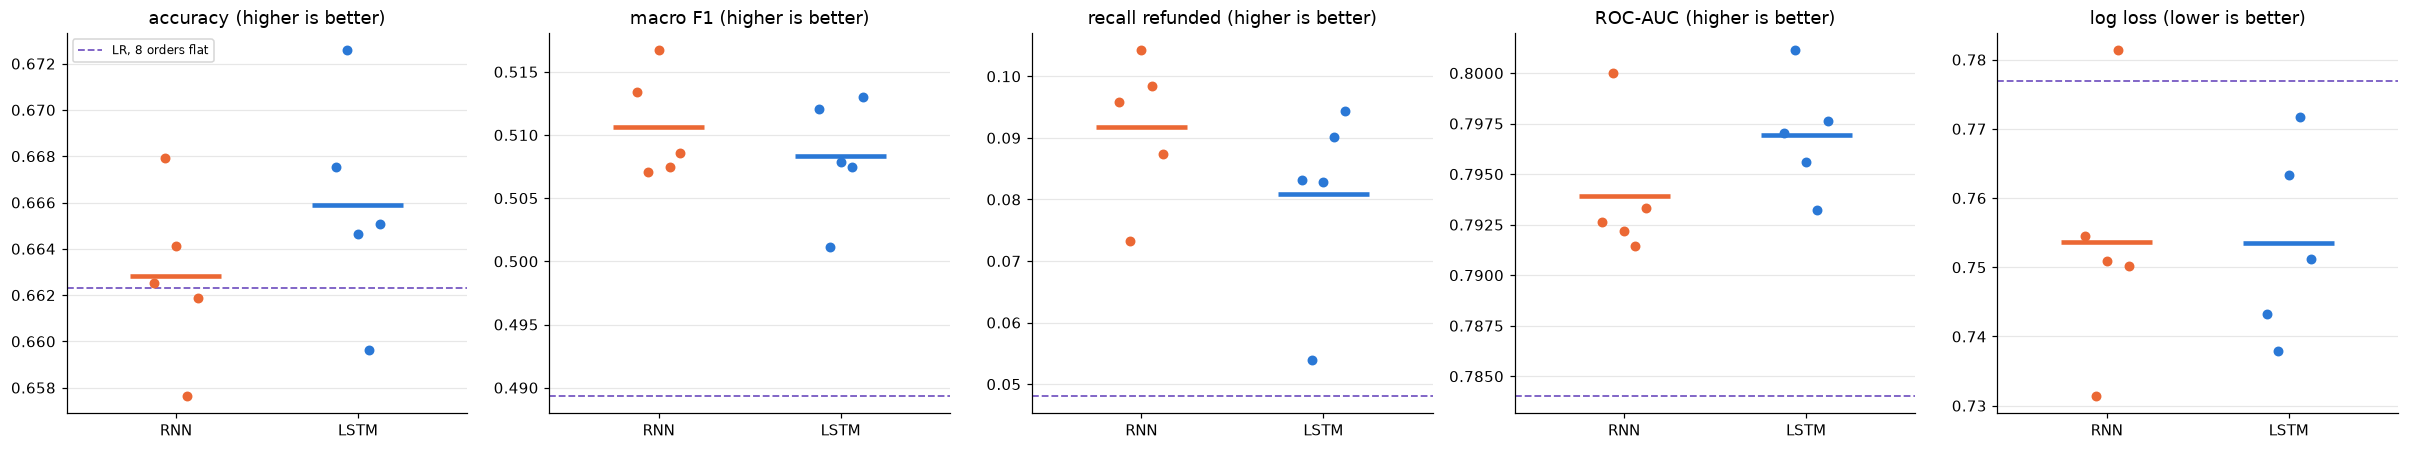

In [15]:
shown = ['accuracy', 'macro F1', 'recall refunded', 'ROC-AUC', 'log loss']
fig, axes = plt.subplots(1, len(shown), figsize=(22, 4.2))
jitter = np.linspace(-0.12, 0.12, len(SEEDS))
for ax, key in zip(axes, shown):
    for j, cell in enumerate(CELLS):
        values = per_seed.loc[per_seed.model == cell, key].to_numpy()
        ax.scatter(j + jitter, values, color=COLORS[cell], s=30, zorder=3)
        ax.hlines(values.mean(), j - 0.25, j + 0.25, color=COLORS[cell], lw=3)
    ax.axhline(seed42.loc['LR, 8 orders flat', key], color=COLORS['LR, 8 orders flat'], ls='--', lw=1.2, label='LR, 8 orders flat')
    ax.set_xticks(range(len(CELLS)), CELLS)
    ax.set(title=f'{key} ({"lower" if key in LOWER else "higher"} is better)', xlim=(-0.6, 1.6))
    ax.grid(axis='x', visible=False)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_ecom_metrics.png')
plt.show()

## 6. Đường học

Trái: train loss, giữa: validation loss (đường đậm = seed 42, đường mảnh = các seed khác), phải: validation accuracy. Validation loss cao hơn train loss ngay từ epoch 1 chủ yếu do tỉ lệ lớp năm 2018 khác (46.7 % canceled so với 32.5 % ở train), như A6 đã phân tích.

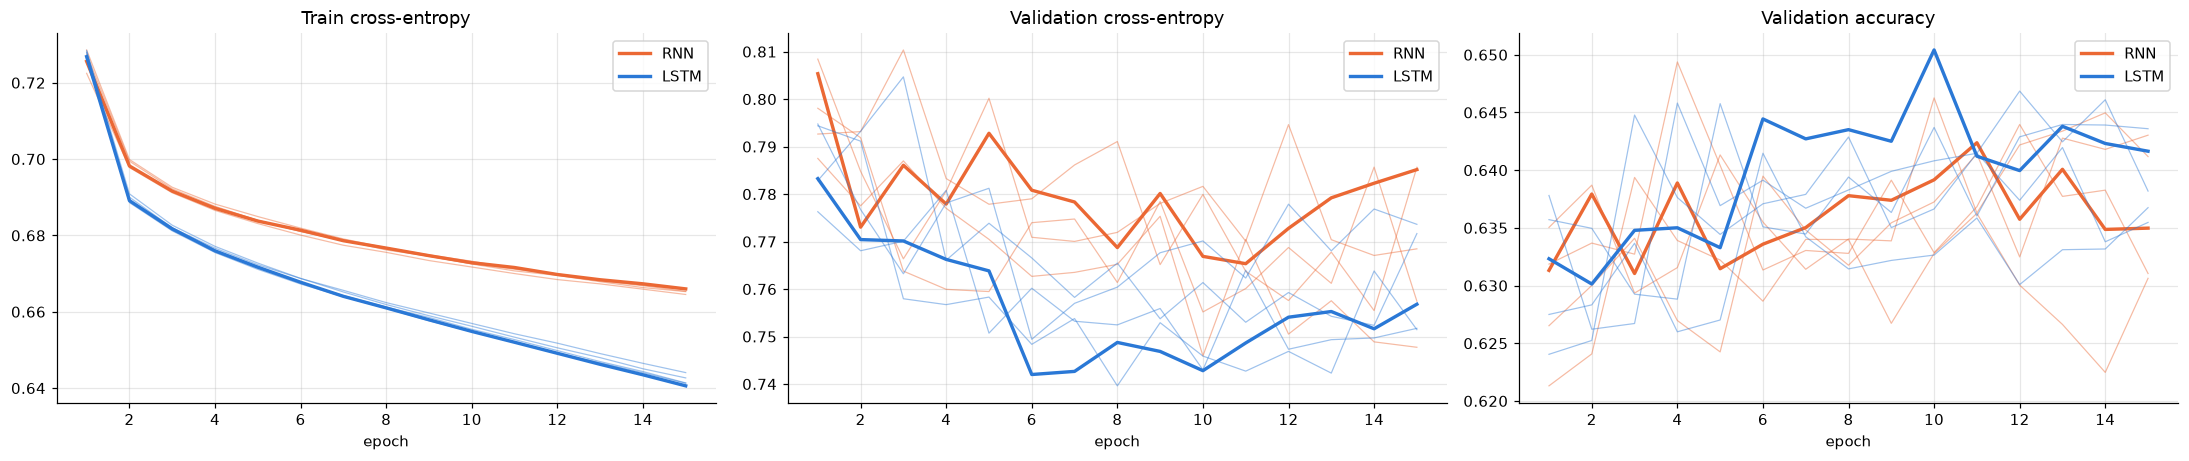

,best epoch (mean),best val loss (mean),final train loss (mean),final val loss (mean)
RNN,9.6,0.7577,0.6654,0.7689
LSTM,8.8,0.7453,0.6420,0.7611


In [16]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(20, 4.3))
for cell in CELLS:
    for seed, r in runs[cell].items():
        style = dict(color=COLORS[cell], lw=2.2 if seed == SEED else 0.8, alpha=1 if seed == SEED else 0.45,
                     label=cell if seed == SEED else None)
        axes[0].plot(epochs, r['history']['loss'], **style)
        axes[1].plot(epochs, r['history']['val_loss'], **style)
        axes[2].plot(epochs, r['history']['val_accuracy'], **style)
axes[0].set(title='Train cross-entropy', xlabel='epoch')
axes[1].set(title='Validation cross-entropy', xlabel='epoch')
axes[2].set(title='Validation accuracy', xlabel='epoch')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_ecom_curves.png')
plt.show()

pd.DataFrame({cell: {'best epoch (mean)': np.mean([r['best_epoch'] for r in runs[cell].values()]),
                     'best val loss (mean)': np.mean([r['best_val_loss'] for r in runs[cell].values()]),
                     'final train loss (mean)': np.mean([r['history']['loss'][-1] for r in runs[cell].values()]),
                     'final val loss (mean)': np.mean([r['history']['val_loss'][-1] for r in runs[cell].values()])}
              for cell in CELLS}).T.round(4)

## 7. Lịch sử khách hàng giúp được bao nhiêu?

Chỉ số trên tập test, nhóm theo số đơn cũ trong chuỗi (0 = đơn đầu tiên của khách, 7 = chuỗi đầy đủ 8 đơn). Với mỗi nhóm, RNN và LSTM lấy trung bình qua 5 seed. Nếu mô hình khai thác được lịch sử, khoảng cách so với "LR, last order" (không có lịch sử) phải tăng khi lịch sử dài hơn.

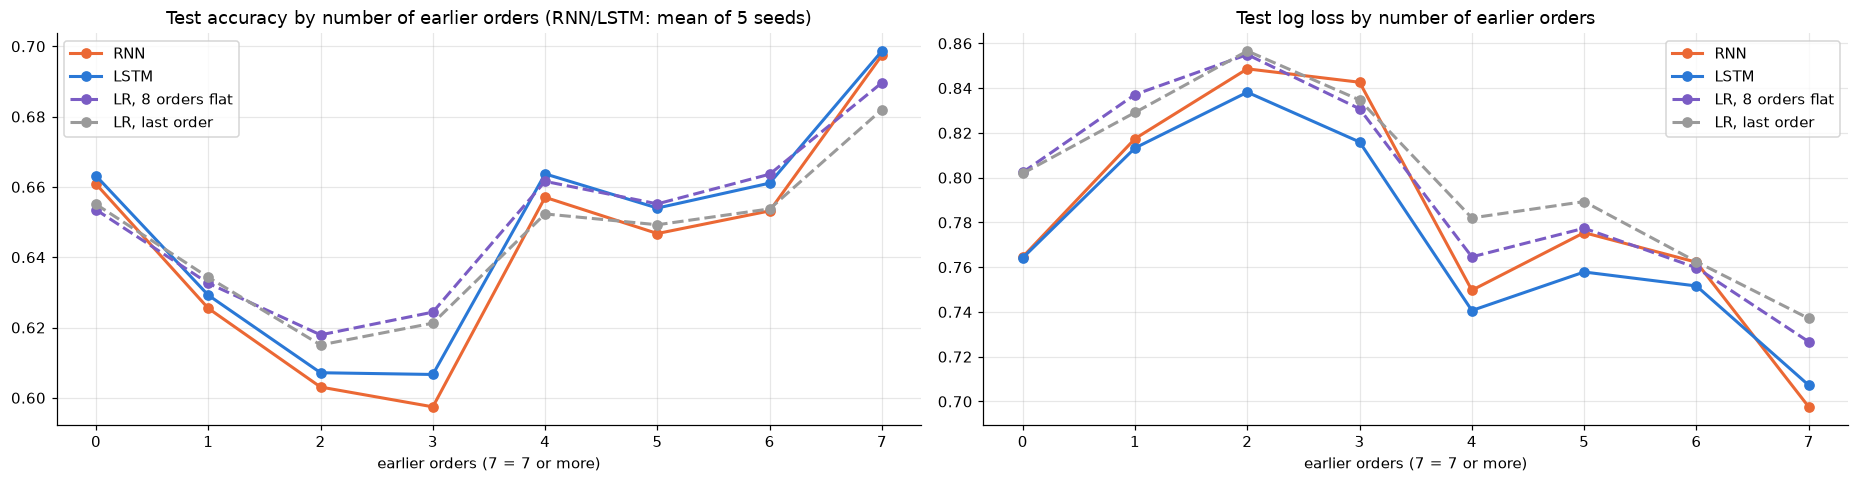

RNN              LSTM          LR, last order           \
  accuracy log loss accuracy log loss       accuracy log loss   
0   0.6608   0.7646   0.6632   0.7642         0.6551   0.8019   
1   0.6255   0.8174   0.6292   0.8133         0.6343   0.8291   
2   0.6031   0.8486   0.6071   0.8382         0.6150   0.8566   
3   0.5974   0.8426   0.6066   0.8159         0.6212   0.8347   
4   0.6570   0.7497   0.6637   0.7406         0.6523   0.7820   
5   0.6467   0.7754   0.6540   0.7578         0.6492   0.7893   
6   0.6532   0.7622   0.6611   0.7516         0.6537   0.7624   
7   0.6974   0.6976   0.6987   0.7073         0.6820   0.7371   

  LR, 8 orders flat          orders  
           accuracy log loss         
0            0.6535   0.8024  11547  
1            0.6326   0.8371   5939  
2            0.6179   0.8550   4177  
3            0.6244   0.8308   3192  
4            0.6616   0.7646   2160  
5            0.6552   0.7774   1682  
6            0.6636   0.7598   1418  
7            0.6896   0.7267  21829

In [17]:
history_length = np.minimum(test_orders.k.to_numpy(), SEQ_LEN - 1)
group_metrics = {'accuracy': lambda t, p: accuracy_score(t, p.argmax(1)), 'log loss': lambda t, p: log_loss(t, p, labels=range(C))}

by_history = {}
for cell in CELLS:
    for metric, f in group_metrics.items():
        by_history[(cell, metric)] = [np.mean([f(y_test[history_length == h], r['test_proba'][history_length == h]) for r in runs[cell].values()])
                                      for h in range(SEQ_LEN)]
for name in ['LR, last order', 'LR, 8 orders flat']:
    for metric, f in group_metrics.items():
        by_history[(name, metric)] = [f(y_test[history_length == h], references[name]['test'][history_length == h]) for h in range(SEQ_LEN)]
by_history = pd.DataFrame(by_history, index=range(SEQ_LEN))
by_history['orders'] = np.bincount(history_length, minlength=SEQ_LEN)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for name in CELLS + ['LR, 8 orders flat', 'LR, last order']:
    style = dict(color=COLORS[name], marker='o', ls='-' if name in CELLS else '--', label=name)
    axes[0].plot(range(SEQ_LEN), by_history[(name, 'accuracy')], **style)
    axes[1].plot(range(SEQ_LEN), by_history[(name, 'log loss')], **style)
axes[0].set(title='Test accuracy by number of earlier orders (RNN/LSTM: mean of 5 seeds)', xlabel='earlier orders (7 = 7 or more)')
axes[1].set(title='Test log loss by number of earlier orders', xlabel='earlier orders (7 = 7 or more)')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_ecom_by_history.png')
plt.show()

by_history.round(4)

## 8. Mô hình nhìn vào bước nào? (độ nhạy theo thời gian)

Với 4,096 chuỗi test có lịch sử đầy đủ, tính gradient của xác suất lớp đúng theo đầu vào ở từng bước, $\left|\partial p(\text{true}) / \partial x_t\right|$ (trung bình trị tuyệt đối, cộng qua 46 đầu vào), cho mô hình seed 42. Đường càng cao ở các bước 1–7 thì mô hình càng dùng nhiều thông tin từ các đơn cũ. Bảng in tỉ lệ độ nhạy nằm ở 7 bước lịch sử, trung bình qua 5 seed.

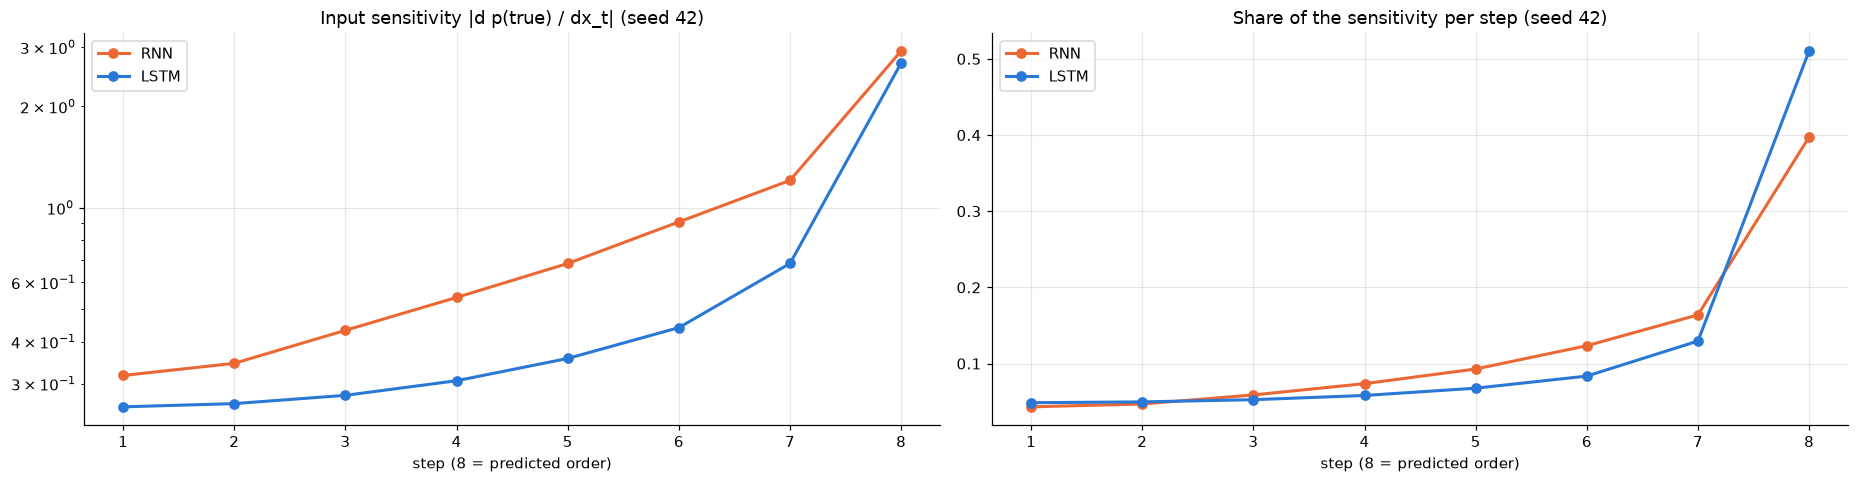

,"history share (steps 1-7), mean",std,seed 42
RNN,0.5849,0.0271,0.6026
LSTM,0.5235,0.0344,0.4896


In [18]:
full = np.flatnonzero(history_length == SEQ_LEN - 1)[:4096]
x_full, y_full = X_test[full], y_test[full]
time_steps = np.arange(1, SEQ_LEN + 1)


def input_sensitivity(model: SeqNet) -> np.ndarray:
    x = torch.from_numpy(x_full).requires_grad_(True)
    model(x).softmax(dim=1).gather(1, torch.from_numpy(y_full)[:, None]).sum().backward()
    return np.abs(x.grad.numpy()).mean(0)                    # (8, 46)


sensitivity = {cell: {seed: input_sensitivity(r['model']) for seed, r in runs[cell].items()} for cell in CELLS}

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for cell in CELLS:
    per_step = sensitivity[cell][SEED].sum(1)
    axes[0].plot(time_steps, per_step, color=COLORS[cell], marker='o', label=cell)
    axes[1].plot(time_steps, per_step / per_step.sum(), color=COLORS[cell], marker='o', label=cell)
axes[0].set(title='Input sensitivity |d p(true) / dx_t| (seed 42)', xlabel='step (8 = predicted order)', yscale='log')
axes[1].set(title='Share of the sensitivity per step (seed 42)', xlabel='step (8 = predicted order)')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_ecom_sensitivity.png')
plt.show()

history_share = {cell: [s.sum(1)[:-1].sum() / s.sum() for s in sensitivity[cell].values()] for cell in CELLS}
pd.DataFrame({cell: {'history share (steps 1-7), mean': np.mean(v), 'std': np.std(v), 'seed 42': history_share[cell][0]}
              for cell, v in history_share.items()}).T.round(4)

Đầu vào lịch sử nào được dùng nhiều nhất? Tổng độ nhạy ở các bước 1–7 theo từng đầu vào (seed 42), 12 đầu vào lớn nhất.

In [19]:
pd.DataFrame({cell: pd.Series(sensitivity[cell][SEED][:-1].sum(0), index=INPUTS) for cell in CELLS}).sort_values('LSTM', ascending=False).head(12).round(4)

,RNN,LSTM
past: canceled,0.1485,0.1413
past: completed,0.1389,0.1259
pay: mcblite,0.2181,0.1046
pay: cashatdoorstep,0.1869,0.1004
type: store credit,0.1539,0.0980
cat: Books,0.1448,0.0827
past: refunded,0.0914,0.0705
pay: customercredit,0.1409,0.0692
pay: ublcreditcard,0.1119,0.0657
pay: jazzwallet,0.1064,0.0652


## 9. Ma trận nhầm lẫn và chi phí

Ma trận chuẩn hóa theo hàng (đường chéo = recall của từng lớp), seed 42.

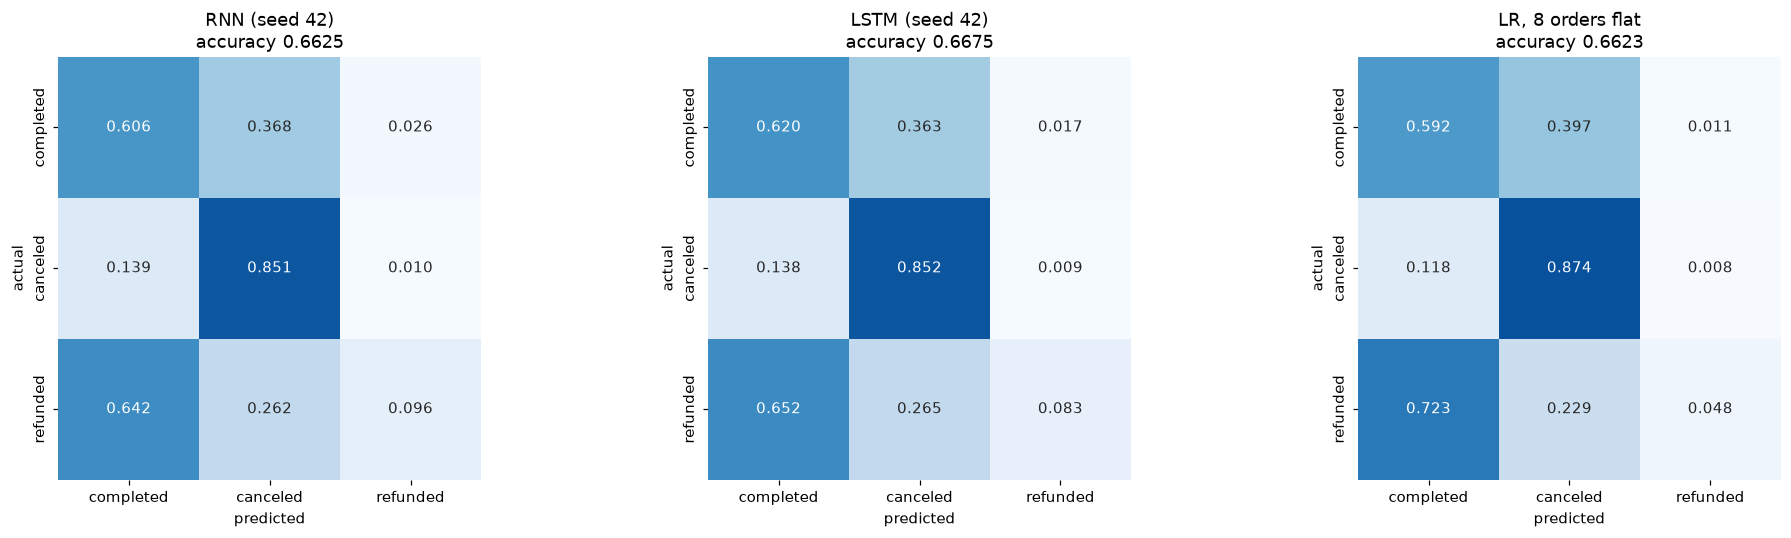

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, CELLS + ['LR, 8 orders flat']):
    proba = runs[name][SEED]['test_proba'] if name in CELLS else references[name]['test']
    cm = confusion_matrix(y_test, proba.argmax(1), labels=range(C), normalize='true')
    sns.heatmap(cm, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1, square=True, cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set(title=f'{name}{" (seed 42)" if name in CELLS else ""}\naccuracy {accuracy_score(y_test, proba.argmax(1)):.4f}', xlabel='predicted', ylabel='actual')
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_ecom_confusion.png')
plt.show()

In [21]:
cost = pd.DataFrame({cell: {'trainable parameters': runs[cell][SEED]['params'],
                            's / epoch (mean)': np.mean([np.mean(r['history']['epoch_time']) for r in runs[cell].values()]),
                            'training time s (mean)': np.mean([r['train_time'] for r in runs[cell].values()]),
                            f'inference ms on {len(X_test):,} orders (mean)': 1000 * np.mean([r['infer_time'] for r in runs[cell].values()])}
                     for cell in CELLS}).T
cost.loc['LSTM / RNN'] = cost.loc['LSTM'] / cost.loc['RNN']
cost.round(2)

,trainable parameters,s / epoch (mean),training time s (mean),"inference ms on 51,944 orders (mean)"
RNN,10307.00,4.27,64.07,158.40
LSTM,40931.00,8.77,131.51,328.61
LSTM / RNN,3.97,2.05,2.05,2.07


## 10. Lưu kết quả và kết luận

Số liệu tổng hợp được ghi vào `results/lstm_ecommerce.json` (chỉ số theo seed, trung bình, đường học, độ nhạy theo bước, chỉ số theo độ dài lịch sử, chi phí).

In [22]:
out = {
    'task': 'ecommerce order outcome (3 classes), sequences of 8 orders',
    'config': {'seq_len': SEQ_LEN, 'hidden': [H1, H2], 'batch': BATCH_SIZE, 'epochs': EPOCHS, 'lr': LR, 'clip': CLIP, 'seeds': SEEDS,
               'n_train': len(X_train), 'n_val': len(X_val), 'n_test': len(X_test)},
    'a6_rnn_reference': A6_RNN,
    'per_seed': per_seed.to_dict(orient='records'),
    'mean': {cell: per_seed[per_seed.model == cell][keys].mean().to_dict() for cell in CELLS},
    'std': {cell: per_seed[per_seed.model == cell][keys].std().to_dict() for cell in CELLS},
    'lstm_wins': wins.to_dict(),
    'references': {name: seed42.loc[name].to_dict() for name in references},
    'curves': {cell: {str(seed): {k: [float(v) for v in r['history'][k]] for k in ['loss', 'val_loss', 'val_accuracy']}
                      for seed, r in runs[cell].items()} for cell in CELLS},
    'sensitivity_per_step_seed42': {cell: (sensitivity[cell][SEED].sum(1) / sensitivity[cell][SEED].sum()).tolist() for cell in CELLS},
    'history_share': {cell: float(np.mean(v)) for cell, v in history_share.items()},
    'by_history': {f'{a} | {b}': by_history[(a, b)].tolist() for a, b in by_history.columns if b != ''} | {'orders': by_history['orders'].tolist()},
    'cost': cost.to_dict(orient='index'),
}
(RESULT_DIR / 'lstm_ecommerce.json').write_text(json.dumps(out, indent=1, default=float), encoding='utf-8')
print('saved', RESULT_DIR / 'lstm_ecommerce.json')

print()
for cell in CELLS:
    m = out['mean'][cell]
    print(f'{cell:<5} (mean of {len(SEEDS)} seeds) accuracy {m["accuracy"]:.4f} | macro F1 {m["macro F1"]:.4f} | recall refunded {m["recall refunded"]:.4f} | '
          f'ROC-AUC {m["ROC-AUC"]:.4f} | log loss {m["log loss"]:.4f}')
for name in references:
    m = seed42.loc[name]
    print(f'{name:<18} accuracy {m["accuracy"]:.4f} | macro F1 {m["macro F1"]:.4f} | log loss {m["log loss"]:.4f}')
print('\nLSTM better than RNN (same seed):', {k: f'{v}/{len(SEEDS)}' for k, v in wins.items()})

saved results/lstm_ecommerce.json

RNN   (mean of 5 seeds) accuracy 0.6628 | macro F1 0.5106 | recall refunded 0.0918 | ROC-AUC 0.7939 | log loss 0.7537
LSTM  (mean of 5 seeds) accuracy 0.6659 | macro F1 0.5083 | recall refunded 0.0809 | ROC-AUC 0.7969 | log loss 0.7535
majority class     accuracy 0.4191 | macro F1 0.1969 | log loss 1.0107
LR, last order     accuracy 0.6584 | macro F1 0.4600 | log loss 0.7819
LR, 8 orders flat  accuracy 0.6623 | macro F1 0.4894 | log loss 0.7770

LSTM better than RNN (same seed): {'accuracy': '5/5', 'balanced acc': '3/5', 'macro F1': '1/5', 'recall completed': '4/5', 'recall canceled': '4/5', 'recall refunded': '1/5', 'MCC': '5/5', 'ROC-AUC': '5/5', 'log loss': '2/5', 'Brier': '3/5'}


**Nhận xét về lần chạy này**

- **Tái lập A6.** RNN seed 42 cho đúng số của A6: accuracy 0.6625, macro F1 0.5134, log loss 0.7545, ROC-AUC 0.7926, best epoch 11. Hai mô hình dùng cùng dữ liệu, cùng split, cùng cách huấn luyện; chỉ khác ô hồi quy.
- **LSTM tốt hơn RNN ở chỉ số tổng thể, cả 5/5 seed:** accuracy 0.6659 so với 0.6628 (+0.003), ROC-AUC 0.7969 so với 0.7939, MCC 0.4136 so với 0.4089. Validation loss tốt nhất cũng thấp hơn ở cả 5 seed (trung bình 0.7453 so với 0.7577), và LSTM đạt mức đó sớm hơn (epoch 6 ở seed 42, RNN ở epoch 11).
- **Lịch sử ngắn và trung bình (1–6 đơn cũ):** LSTM có accuracy cao hơn và log loss thấp hơn RNN ở mọi nhóm. Ví dụ với 3 đơn cũ: log loss 0.816 so với 0.843. Với đủ 7 đơn cũ trở lên thì accuracy gần bằng nhau (0.699 so với 0.697), nhưng log loss của LSTM lại kém hơn (0.707 so với 0.698).
- **Chênh lệch nhỏ, và có chỉ số LSTM không thắng.** Macro F1 (0.5083 so với 0.5106) và recall của lớp *refunded* (0.081 so với 0.092) thấp hơn RNN. Log loss gần như bằng nhau (0.7535 so với 0.7537). Lý do: chuỗi chỉ dài 8 bước, nên vanishing gradient không phải nút thắt chính. A6 đo được gradient ở bước 1 vẫn còn 0.15 (lớp 1) so với bước 8. Lớp *refunded* khó vì lúc đặt hàng nó trông giống một đơn *completed*. Cổng của LSTM không giải quyết được vấn đề đó.
- **Chi phí:** LSTM có số tham số gấp ≈ 4 lần (40,931 so với 10,307), huấn luyện và suy luận chậm hơn ≈ 2 lần.